In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.formula.api as smf

import pickle
import os

### Question 2
* Do customer service calls signal frustration or engagement?
Churn climbs with call volume, from about 65% for customers with zero calls to over 90% for those with 5+. That raises a business question: at how many calls should a customer be escalated to retention outreach? You could also test whether calls matter on their own or just overlap with inactivity.

In [2]:
dataset = '../data/customer_churn_clean.csv'
result_dir = '../result'

df = pd.read_csv(dataset)
df.head()

,Unnamed: 0,customer_id,gender,region,subscription_plan,payment_method,age,days_since_last_login,customer_service_calls,monthly_spend,churn
0,0,10001,Male,East,Basic,PayPal,27.0,27,1.0,61.08,0
1,1,10002,NaN,West,Pro,PayPal,55.0,146,2.0,73.09,0
2,2,10003,Female,West,Pro,E-Wallet,NaN,147,2.0,116.30,1
3,3,10004,Female,South,Basic,Credit Card,NaN,34,1.0,0.58,1
4,4,10005,Male,North,Basic,Crypto,30.0,146,3.0,46.35,1


#### Analysis Variables
* customer_service_calls
    - total number of support interactions
* days_since_last_login
    - time (in days) since last login
* churn
    - target variable; 
        - 1 = churned
        - 2 = retained

In [3]:
# Subsetting the dataset with only required variables
# Dropping null values for logistic regression analysis

calls_churn = df[['customer_service_calls','days_since_last_login','churn']].dropna()
cc_rate = calls_churn[['customer_service_calls','churn']].groupby(['customer_service_calls'])['churn'].mean()
cc_rate

customer_service_calls
0.0    0.654685
1.0    0.723470
2.0    0.779255
3.0    0.835710
4.0    0.863329
5.0    0.927536
6.0    0.935065
7.0    1.000000
8.0    1.000000
9.0    1.000000
Name: churn, dtype: float64

In [4]:
# Checking for calls class distribution
# May explain why calls above 6 are 100%

calls_dist = calls_churn[['customer_service_calls','churn']].groupby(['customer_service_calls'])['churn'].count()
calls_dist

customer_service_calls
0.0    1697
1.0    2893
2.0    2632
3.0    1613
4.0     739
5.0     276
6.0      77
7.0      19
8.0       3
9.0       1
Name: churn, dtype: int64

**_Customer Service Calls Counts_**
* Customer service calls greater than 6 account for fewer than 20 cases, offering negligible additional predictive signal for churn. To reduce noise from sparse extremes, call counts are capped at 6.

In [5]:
calls_churn.customer_service_calls = calls_churn.customer_service_calls.clip(upper=6)
cc_rate = calls_churn[['customer_service_calls','churn']].groupby(['customer_service_calls'])['churn'].mean()
cc_rate

customer_service_calls
0.0    0.654685
1.0    0.723470
2.0    0.779255
3.0    0.835710
4.0    0.863329
5.0    0.927536
6.0    0.950000
Name: churn, dtype: float64

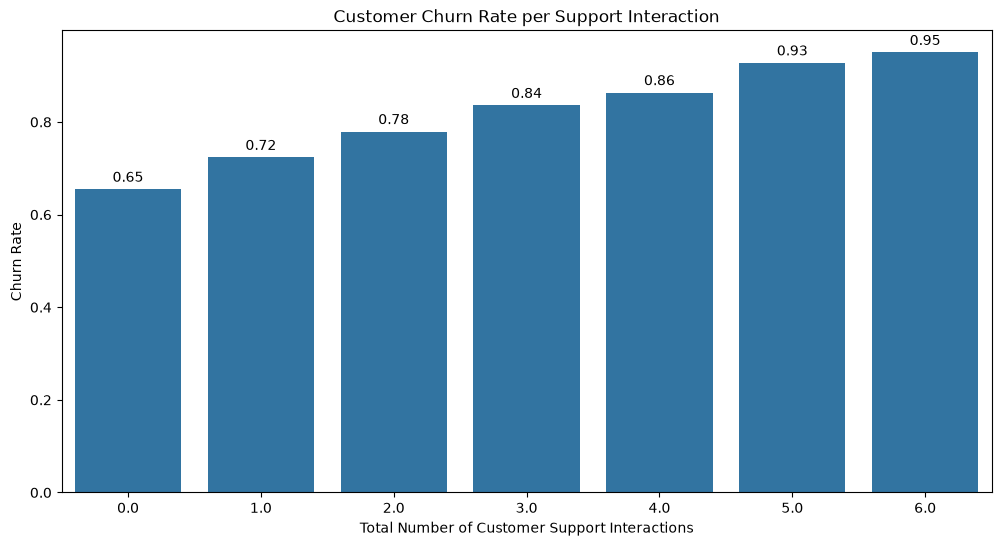

In [6]:
# Visualizing Customer 
# Churn Rate per Made Customer Support Interaction

fig, ax = plt.subplots(figsize=(12,6))
p = sns.barplot(
    cc_rate,
    ax=ax
)
for p in p.patches:
    height=p.get_height()
    ax.annotate(
        f'{height:.2f}',
        xy=(p.get_x()+p.get_width()/2, height),
        xytext=(0,3),
        textcoords='offset points',
        ha='center',
        va='bottom'
    )
plt.xlabel('Total Number of Customer Support Interactions')
plt.ylabel('Churn Rate')
plt.title('Customer Churn Rate per Support Interaction')
plt.show()

**_Customer Churn Rate per Made Calls_**
* The plot shows that customer with higher support interaction are more likely to churn

#### Performing Hypothesis Testing in Logistic Regression and Results Analysis

$H_0$ = The regression coefficient ($β_r$) = 0 
        Customer service calls has no effect on the log-odds (probability) of customer churn

$H_1$ = The regression coefficient ($β_r$) != 0
        Customer service calls has effect on the log-odds (probability) of customer churn

In [7]:
formula = "churn ~ C(customer_service_calls)"
model = smf.logit(formula, data=calls_churn).fit()
model_summary = model.summary()
model_summary

Optimization terminated successfully.
         Current function value: 0.532239
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  churn   No. Observations:                 9950
Model:                          Logit   Df Residuals:                     9943
Method:                           MLE   Df Model:                            6
Date:                Wed, 28 Oct 2026   Pseudo R-squ.:                 0.02801
Time:                        16:20:41   Log-Likelihood:                -5295.8
converged:                       True   LL-Null:                       -5448.4
Covariance Type:            nonrobust   LLR p-value:                 6.064e-63
====================================================================================================
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                            0.6397      0.051     12.530      0.000       0.540       0.740
C(customer_service_calls)[T.1.0]     0.3220      0.066      4.892      0.000       0.193       0.451
C(customer_service_calls)[T.2.0]     0.6216      0.069      8.958      0.000       0.486       0.758
C(customer_service_calls)[T.3.0]     0.9870      0.084     11.695      0.000       0.822       1.152
C(customer_service_calls)[T.4.0]     1.2035      0.119     10.144      0.000       0.971       1.436
C(customer_service_calls)[T.5.0]     1.9097      0.238      8.033      0.000       1.444       2.376
C(customer_service_calls)[T.6.0]     2.3047      0.462      4.992      0.000       1.400       3.210
====================================================================================================
"""

**_Logit Regression Results_**

Customer service calls or support interactions shows a positive gradual increase of customer churn and all categories are statistically significant

#### Results Inverse Transformation
- Odds Ratio :  Multiplicative effect on the odds.
    * $Odds_r$ < 1 : Negative relationship
    * $Odds_r$ = 1 : No relationship
    * $Odds_r$ > 1 : Positive relashionship

- % Change in Odds : increase/decrease percent on the odds
- Total Odds : Combined odds of the event occurring for that specific profile.
- Predicted Risk : Final probability of that outcome occuring

In [8]:
def inverse_transformation(model):
    params = model.params.drop('Intercept')
    intercept = model.params.iloc[0]

    odds_df = pd.DataFrame({
        'Coef':params,
        'Odds Ratio': np.exp(params),
        r'% Change in Odds': round((np.exp(params)-1)*100,2),
        'Total Odds': np.exp(params+intercept),
        'Predicted Risk':round((np.exp(params+intercept)/(1+(np.exp(params+intercept))))*100,2)
    })

    intercept_df = pd.DataFrame({
        'Coef':intercept,
        'Odds Ratio':'---',
        r'% Change in Odds': '---',
        'Total Odds': np.exp(intercept),
        'Predicted Risk':round(np.exp(intercept)/(1+np.exp(intercept))*100,2)
    }, index=['C(customer_service_calls)[T.0.0]'])

    results = pd.concat([intercept_df, odds_df])

    return results
calls_churn_logreg = inverse_transformation(model)
calls_churn_logreg

,Coef,Odds Ratio,% Change in Odds,Total Odds,Predicted Risk
C(customer_service_calls)[T.0.0],0.639696,---,---,1.895904,65.47
C(customer_service_calls)[T.1.0],0.322046,1.379948,37.99,2.616250,72.35
C(customer_service_calls)[T.2.0],0.621636,1.861972,86.2,3.530120,77.93
C(customer_service_calls)[T.3.0],0.986951,2.683043,168.3,5.086792,83.57
C(customer_service_calls)[T.4.0],1.203522,3.33183,233.18,6.316832,86.33
C(customer_service_calls)[T.5.0],1.909749,6.751395,575.14,12.800000,92.75
C(customer_service_calls)[T.6.0],2.304743,10.021602,902.16,19.000000,95.00


In [9]:
calls_churn_logreg[['Predicted Risk']]

,Predicted Risk
C(customer_service_calls)[T.0.0],65.47
C(customer_service_calls)[T.1.0],72.35
C(customer_service_calls)[T.2.0],77.93
C(customer_service_calls)[T.3.0],83.57
C(customer_service_calls)[T.4.0],86.33
C(customer_service_calls)[T.5.0],92.75
C(customer_service_calls)[T.6.0],95.00


In [10]:
# Saving results
results_path = 'result/'
def save_result(result_name:str, result):
    os.makedirs('result', exist_ok=True)

    with open(results_path+result_name+'.pickle', 'wb') as to_write:
        pickle.dump(result, to_write)

save_result('calls_churn_analysis_result', calls_churn_logreg)

**_Inverse Transformation Results Analysis_**
1. The computed predicted risks from the results of **_Logit Regression Results_** validates the calculated churn rate from **_Customer Churn Rate per Made Calls_** plot.
2. At 0 calls, the predicted churn rate is already at `65%` mark. This requires further analysis to determine if support interaction matter on their own or overlaps with inactivity

**_Hypothesis Decision_**
* Reject the null hypothesis ($H_0$)
* Customer service calls or support interactions has a positive effrct on the log-odds (probbability) of customer curn

**_Next Steps_**
* Performing logistic regression of customer service calls while controlling inactivity

In [11]:
# Structuring days_since_last_login to categorical variable
# Subsetting the dataset with only required variables
# Dropping null values for logistic regression analysis

cccc = calls_churn.copy()

def days_to_months(days):
    if days <= 30:
        return '30d'
    if days <= 60:
        return '60d'
    if days <= 90:
        return '90d'
    if days <= 120:
        return '120d'
    if days <= 150:
        return '150d'
    if days <= 180:
        return '180d'

cccc.days_since_last_login = cccc.days_since_last_login.apply(days_to_months)
days_order = [
    '30d','60d','90d','120d','150d','180d'
]
cccc.days_since_last_login = pd.Categorical(cccc.days_since_last_login, categories=days_order, ordered=True)

np.unique(cccc.days_since_last_login)

array(['120d', '150d', '180d', '30d', '60d', '90d'], dtype=object)

#### Performing Hypothesis Testing in Logistic Regression and Results Analysis

$H_0$ = The regression coefficient ($β_r$) = 0 
        Customer service calls has no effect on the log-odds (probability) of customer churn while holding inactivity

$H_1$ = The regression coefficient ($β_r$) != 0
        Customer inactivity has effect on the log-odds (probability) of customer churn while holding inactivity

In [12]:
# Creating formula
formula_2 = 'churn ~ C(customer_service_calls) + C(days_since_last_login)'

# Modeling logit regression
model_2 = smf.logit(formula_2, data=cccc).fit()

# Summary Analysis/Interpretation
summary_2 = model_2.summary()
summary_2

Optimization terminated successfully.
         Current function value: 0.495151
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  churn   No. Observations:                 9950
Model:                          Logit   Df Residuals:                     9938
Method:                           MLE   Df Model:                           11
Date:                Wed, 28 Oct 2026   Pseudo R-squ.:                 0.09575
Time:                        16:20:42   Log-Likelihood:                -4926.8
converged:                       True   LL-Null:                       -5448.4
Covariance Type:            nonrobust   LLR p-value:                9.060e-217
====================================================================================================
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           -0.2367      0.071     -3.347      0.001      -0.375      -0.098
C(customer_service_calls)[T.1.0]     0.3409      0.069      4.936      0.000       0.206       0.476
C(customer_service_calls)[T.2.0]     0.6906      0.073      9.510      0.000       0.548       0.833
C(customer_service_calls)[T.3.0]     1.0756      0.088     12.257      0.000       0.904       1.248
C(customer_service_calls)[T.4.0]     1.3266      0.122     10.842      0.000       1.087       1.566
C(customer_service_calls)[T.5.0]     2.0640      0.241      8.547      0.000       1.591       2.537
C(customer_service_calls)[T.6.0]     2.5048      0.466      5.370      0.000       1.591       3.419
C(days_since_last_login)[T.60d]      0.3203      0.073      4.365      0.000       0.176       0.464
C(days_since_last_login)[T.90d]      0.7219      0.076      9.452      0.000       0.572       0.872
C(days_since_last_login)[T.120d]     1.1168      0.080     13.892      0.000       0.959       1.274
C(days_since_last_login)[T.150d]     1.5844      0.090     17.636      0.000       1.408       1.760
C(days_since_last_login)[T.180d]     2.0208      0.102     19.906      0.000       1.822       2.220
====================================================================================================
"""

**_Logit Regression Result - Customer Service Calls + Inactivity_**

All customer service calls category shows a positive gradual increase of customer churn and are statistically significant while controlling for customer inactivity.

#### Results Inverse Transformation
- Odds Ratio :  Multiplicative effect on the odds.
    * $Odds_r$ < 1 : Negative relationship
    * $Odds_r$ = 1 : No relationship
    * $Odds_r$ > 1 : Positive relashionship

- % Change in Odds : increase/decrease percent on the odds
- Total Odds : Combined odds of the event occurring for that specific profile.
- Predicted Risk : Final probability of that outcome occuring

In [13]:
def odds_risks(model):
    params = model.params.drop('Intercept',)
    intercept = model.params.iloc[0]

    odds_df = pd.DataFrame({
        'Coef':params,
        'Odds Ratio':np.exp(params),
        r"% Change in Odds":round((np.exp(params)-1)*100,2),
        'Total Odds':np.exp(params+intercept),
        'Predicted Risks':round((np.exp(params+intercept)/(1+np.exp(params+intercept)))*100,2)
    })

    intercept_df = pd.DataFrame({
        'Coef':intercept,
        'Odds Ratio':'---',
        r'% Change in Odds':'---',
        'Total Odds': round(np.exp(intercept),2),
        'Predicted Risks':round((np.exp(intercept)/(1+np.exp(intercept)))*100,2)
    }, index=['C(customer_service_calls)[T.0.0]'])

    results = pd.concat([intercept_df, odds_df])
    return results

cccc_logreg = odds_risks(model_2)
cccc_logreg

,Coef,Odds Ratio,% Change in Odds,Total Odds,Predicted Risks
C(customer_service_calls)[T.0.0],-0.236705,---,---,0.790000,44.11
C(customer_service_calls)[T.1.0],0.340860,1.406156,40.62,1.109772,52.60
C(customer_service_calls)[T.2.0],0.690623,1.994959,99.5,1.574469,61.16
C(customer_service_calls)[T.3.0],1.075552,2.931611,193.16,2.313697,69.82
C(customer_service_calls)[T.4.0],1.326567,3.768087,276.81,2.973864,74.84
C(customer_service_calls)[T.5.0],2.064009,7.87749,687.75,6.217103,86.14
C(customer_service_calls)[T.6.0],2.504764,12.240664,1124.07,9.660624,90.62
C(days_since_last_login)[T.60d],0.320301,1.377542,37.75,1.087189,52.09
C(days_since_last_login)[T.90d],0.721936,2.058414,105.84,1.624550,61.90
C(days_since_last_login)[T.120d],1.116850,3.055214,205.52,2.411248,70.69


In [14]:
# Save results
save_result('calls_inactivity_churn_analysis_result',cccc_logreg)

In [15]:
# Comparing the 2 Logit Regression Results Summary

with open(results_path+'calls_churn_analysis_result.pickle', 'rb') as to_read:
    summary_1 = pickle.load(to_read)

In [16]:
summary_1['Predicted Risk']

C(customer_service_calls)[T.0.0]    65.47
C(customer_service_calls)[T.1.0]    72.35
C(customer_service_calls)[T.2.0]    77.93
C(customer_service_calls)[T.3.0]    83.57
C(customer_service_calls)[T.4.0]    86.33
C(customer_service_calls)[T.5.0]    92.75
C(customer_service_calls)[T.6.0]    95.00
Name: Predicted Risk, dtype: float64

In [17]:
cccc_logreg['Predicted Risks'][:7]

C(customer_service_calls)[T.0.0]    44.11
C(customer_service_calls)[T.1.0]    52.60
C(customer_service_calls)[T.2.0]    61.16
C(customer_service_calls)[T.3.0]    69.82
C(customer_service_calls)[T.4.0]    74.84
C(customer_service_calls)[T.5.0]    86.14
C(customer_service_calls)[T.6.0]    90.62
Name: Predicted Risks, dtype: float64

In [18]:
churn_diff = summary_1['Predicted Risk']-cccc_logreg['Predicted Risks'][:7]

In [19]:
comp_df = pd.DataFrame({
    'Churn ~ Customer Service Calls':(
        summary_1['Predicted Risk']
    ),
    'Churn ~ Customer Service Calls + Inactivity':(
        cccc_logreg['Predicted Risks'][:7]
    ),
    'Churn Difference':(
        churn_diff
    )
})

comp_df

,Churn ~ Customer Service Calls,Churn ~ Customer Service Calls + Inactivity,Churn Difference
C(customer_service_calls)[T.0.0],65.47,44.11,21.36
C(customer_service_calls)[T.1.0],72.35,52.60,19.75
C(customer_service_calls)[T.2.0],77.93,61.16,16.77
C(customer_service_calls)[T.3.0],83.57,69.82,13.75
C(customer_service_calls)[T.4.0],86.33,74.84,11.49
C(customer_service_calls)[T.5.0],92.75,86.14,6.61
C(customer_service_calls)[T.6.0],95.00,90.62,4.38


**_Inverse Transportation Results Analysis - Customer Service Calls + Inactivity_**

1. Adding inactivity lowers predicted churn at every call level (by 4 to 21 points, holding
   inactivity at 0), so part of the churn attributed to support calls in the calls-only model
   is explained by inactivity.
2. The gap shrinks as calls rise (21.4 points at 0 calls, 4.4 at 6 calls). At high call counts,
   even customers with no inactivity have very high predicted churn (86 to 91% at 5 to 6 calls),
   indicating the customer service calls matter on their own

**_Next Step_**
1. Identifying if setting customer support interaction threshold of 4 calls yields a positive result.


#### Customer Lifetime Value based on Customer Service Calls

In [20]:
# Checking mean and median before choosing a central measure

calls_ltv = df[['customer_service_calls','monthly_spend','churn']]
calls_ltv.dropna(inplace=True)

C:\Users\jlmor\AppData\Local\Temp\ipykernel_13384\1767394920.py:4: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  calls_ltv.dropna(inplace=True)


In [21]:
calls_ltv.shape

(9393, 3)

<Axes: ylabel='monthly_spend'>

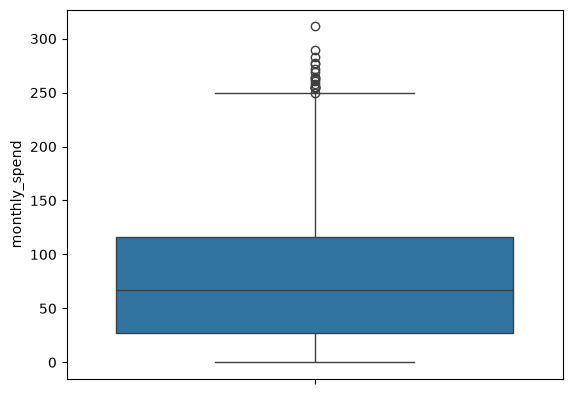

In [22]:
sns.boxplot(
    calls_ltv.monthly_spend
)

**_Monthly Spend Boxplot_**
* A monthly spend of $250 is considered an outlier.
* The outliers are not dropped since marked outliers are a valid data points and is not an error

In [23]:
# Capping customer service calls to 6
calls_ltv.customer_service_calls=calls_ltv.customer_service_calls.clip(upper=6)
calls_ltv.customer_service_calls.describe()

count    9393.000000
mean        1.807090
std         1.347455
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         6.000000
Name: customer_service_calls, dtype: float64

In [24]:
# Determining the mean and median
print(calls_ltv.monthly_spend.mean(), calls_ltv.monthly_spend.median())

76.02745661662941 66.68


In [25]:
# Median will be used

group_cltv = calls_ltv.groupby(['customer_service_calls']).agg(
    total_calls = pd.NamedAgg(column='customer_service_calls', aggfunc='count'),
    ave_spend = pd.NamedAgg(column='monthly_spend', aggfunc='median')
).reset_index()
group_cltv['Churn'] = cccc_logreg['Predicted Risks'][:7].values/100
group_cltv

,customer_service_calls,total_calls,ave_spend,Churn
0,0.0,1598,65.875,0.4411
1,1.0,2730,67.035,0.5260
2,2.0,2478,66.925,0.6116
3,3.0,1521,65.870,0.6982
4,4.0,700,68.770,0.7484
5,5.0,271,60.190,0.8614
6,6.0,95,78.590,0.9062


**_Insights_**

* Support Interaction:
    - Customers with 4 or less service calls mostly spend \$65 - 69$
    - Customers with 5 service calls mostly spend $60
    - Customers with 6 or more service calls have the highest average spend of $78.6

In [26]:
# Calculating total customers lost
group_cltv['lost_customers'] = group_cltv.total_calls*group_cltv.Churn

# Calculating customer Lifetime Value
group_cltv['ltv'] = group_cltv.ave_spend/group_cltv.Churn

# Calculating total Customer Lifetime Value Lost
group_cltv['total_ltv_lost'] = (group_cltv.lost_customers*group_cltv.ave_spend)* 12

# Calculating Loss Share Percentage
# The percentage of the lost revenue
group_cltv['loss_share'] = round((group_cltv.total_ltv_lost/sum(group_cltv.total_ltv_lost))*100,2)

group_cltv


,customer_service_calls,total_calls,ave_spend,Churn,lost_customers,ltv,total_ltv_lost,loss_share
0,0.0,1598,65.875,0.4411,704.8778,149.342553,5.572059e+05,12.52
1,1.0,2730,67.035,0.5260,1435.9800,127.442966,1.155131e+06,25.95
2,2.0,2478,66.925,0.6116,1515.5448,109.426095,1.217134e+06,27.35
3,3.0,1521,65.870,0.6982,1061.9622,94.342595,8.394174e+05,18.86
4,4.0,700,68.770,0.7484,523.8800,91.889364,4.323267e+05,9.71
5,5.0,271,60.190,0.8614,233.4394,69.874623,1.686086e+05,3.79
6,6.0,95,78.590,0.9062,86.0890,86.724785,8.118881e+04,1.82


In [27]:
group_cltv[['customer_service_calls','Churn','lost_customers','total_ltv_lost','loss_share']]

,customer_service_calls,Churn,lost_customers,total_ltv_lost,loss_share
0,0.0,0.4411,704.8778,5.572059e+05,12.52
1,1.0,0.5260,1435.9800,1.155131e+06,25.95
2,2.0,0.6116,1515.5448,1.217134e+06,27.35
3,3.0,0.6982,1061.9622,8.394174e+05,18.86
4,4.0,0.7484,523.8800,4.323267e+05,9.71
5,5.0,0.8614,233.4394,1.686086e+05,3.79
6,6.0,0.9062,86.0890,8.118881e+04,1.82


**Conclusion**

1. Customers with 0-3 support calls account for 84.7% of projected lost revenue
   (12.52 + 25.95 + 27.35 + 18.86). Customers with 4-6 calls account for the
   remaining 15.3%.

2. This largely reflects volume: 8,327 of 9,393 customers (88.7%) fall in the 0-3
   group, and the 1- and 2-call groups alone hold 53.3% of the loss. Per customer,
   predicted churn rises with every additional call, from 44.1% at 0 calls to 69.8%
   at 3 calls, 74.8% at 4 calls and 90.6% at 6 calls.

3. A trigger at 4+ calls would cover 15.3% of projected loss while reaching 11.3% of
   customers (1,066). A trigger at 3+ calls would cover 34.2% while reaching 27.5%
   (2,587).